In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('SuperMarket.csv')
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.22,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.048,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,NaN,10:37:00 AM,E-wallet,604.17,4.761905,30.2085,5.3


In [2]:
df.shape[0]

1014

In [3]:
df.shape[1]

17

In [4]:
df.dtypes

Invoice ID                     str
Branch                         str
City                           str
   Customer type               str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Sales                          str
Date                           str
Time                           str
Payment                        str
   cogs                    float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

In [5]:
df.isnull().sum()

Invoice ID                  0
Branch                      0
City                        0
   Customer type            0
Gender                      0
Product line                0
Unit price                 24
Quantity                    0
Tax 5%                      0
Sales                      20
Date                       12
Time                        0
Payment                     0
   cogs                     0
gross margin percentage     0
gross income                0
Rating                      0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(14)

In [7]:
df.describe()

,Unit price,Quantity,Tax 5%,cogs,gross margin percentage,gross income,Rating
count,990.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,55.520333,5.502959,15.336872,306.737436,4.761905,15.336872,6.960454
std,26.330508,2.927133,11.685945,233.718896,0.000000,11.685945,1.721264
min,10.080000,1.000000,0.508500,10.170000,4.761905,0.508500,4.000000
25%,33.202500,3.000000,5.864625,117.292500,4.761905,5.864625,5.500000
50%,54.890000,5.000000,12.066000,241.320000,4.761905,12.066000,6.900000
75%,77.667500,8.000000,22.428000,448.560000,4.761905,22.428000,8.475000
max,99.960000,10.000000,49.650000,993.000000,4.761905,49.650000,10.000000


In [8]:
df.nunique()

Invoice ID                 1000
Branch                        8
City                          3
   Customer type              2
Gender                        4
Product line                  6
Unit price                  921
Quantity                     10
Tax 5%                      990
Sales                       970
Date                         89
Time                        506
Payment                       6
   cogs                     990
gross margin percentage       1
gross income                990
Rating                       61
dtype: int64

My Observations :

1-The dataset includes numerical and categorical columns.

2-The date column needs to be converted to the appropriate date format.

3-The dataset needs to be cleaned before performing data analysis to ensure accurate results.

In [9]:
df.rename(columns={'Invoice ID': 'Invoice_ID',
                    'Branch': 'Branch',
                    'City': 'City',
                    '   Customer type': 'Customer_type',
                    'Gender': 'Gender',
                    'Product line': 'Product_line', 
                    'Unit price': 'Unit_price', 
                    'Quantity': 'Quantity', 
                    'Tax 5%': 'Tax_5%', 
                    'Sales': 'Sales',
                    'Date': 'Date', 
                    'Time': 'Time',
                    'Payment    ': 'Payment',
                    '   cogs': 'Cogs',
                    'gross margin percentage': 'gross_margin_percentage',
                    'gross income': 'gross_income', 
                    'Rating': 'Rating'} , inplace=True)

In [10]:
df.columns

Index(['Invoice_ID', 'Branch', 'City', 'Customer_type', 'Gender',
       'Product_line', 'Unit_price', 'Quantity', 'Tax_5%', 'Sales', 'Date',
       'Time', 'Payment', 'Cogs', 'gross_margin_percentage', 'gross_income',
       'Rating'],
      dtype='str')

In [11]:
df.fillna({"Unit_price":"unknown" , "Sales":"unknown" ,"Date":"unknown" } , inplace=True)

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_margin_percentage,gross_income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.22,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.048,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,unknown,10:37:00 AM,E-wallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1009,886-18-2897,Alex,Yangon,Normal,Female,Food and beverages,56.56,5,14.1400,296.94,3/22/2019,7:06:00 PM,Credit card,282.80,4.761905,14.1400,4.5
1010,602-16-6955,Cairo,Mandalay,Normal,Female,Sports and travel,76.6,10,38.3000,804.3,1/24/2019,6:10:00 PM,Ewallet,766.00,4.761905,38.3000,6.0
1011,745-74-0715,Alex,Yangon,Normal,Male,Electronic accessories,58.03,2,5.8030,121.863,3/10/2019,8:46:00 PM,Ewallet,116.06,4.761905,5.8030,8.8
1012,690-01-6631,Cairo,Mandalay,Normal,Male,Fashion accessories,17.49,10,8.7450,183.645,2/22/2019,6:35:00 PM,Ewallet,174.90,4.761905,8.7450,6.6


In [12]:
df.isna().sum()

Invoice_ID                 0
Branch                     0
City                       0
Customer_type              0
Gender                     0
Product_line               0
Unit_price                 0
Quantity                   0
Tax_5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
Cogs                       0
gross_margin_percentage    0
gross_income               0
Rating                     0
dtype: int64

In [13]:
df = df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop("gross_margin_percentage" , axis=1)

In [16]:
df

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.22,3/8/2019,10:29:00 AM,Cash,76.40,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.048,1/27/2019,8:33:00 PM,Ewallet,465.76,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,unknown,10:37:00 AM,E-wallet,604.17,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,1:46:00 PM,Ewallet,40.35,2.0175,6.2
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.49,3/2/2019,5:16:00 PM,Ewallet,973.80,48.6900,4.4
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.432,2/9/2019,1:22:00 PM,Cash,31.84,1.5920,7.7
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.111,2/22/2019,3:33:00 PM,Cash,65.82,3.2910,4.1


In [17]:
df["Date"] = df["Date"].replace("unknown", pd.NaT)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Unit_price"] = pd.to_numeric(df["Unit_price"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Tax_5%"] = pd.to_numeric(df["Tax_5%"], errors="coerce")
df

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,1:08:00 PM,Ewallet,522.83,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.22,2019-03-08,10:29:00 AM,Cash,76.40,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,1:23:00 PM,Credit card,324.31,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.048,2019-01-27,8:33:00 PM,Ewallet,465.76,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,NaT,10:37:00 AM,E-wallet,604.17,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,2019-01-29,1:46:00 PM,Ewallet,40.35,2.0175,6.2
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.49,2019-03-02,5:16:00 PM,Ewallet,973.80,48.6900,4.4
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.432,2019-02-09,1:22:00 PM,Cash,31.84,1.5920,7.7
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.111,2019-02-22,3:33:00 PM,Cash,65.82,3.2910,4.1


In [18]:
df.sort_values(by="Date", ascending=True, inplace=True)
df

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_income,Rating
970,746-04-1077,Cairo,Mandalay,Member,Female,Food and beverages,84.63,10,42.3150,888.615,2019-01-01,11:36:00 AM,Credit card,846.30,42.3150,9.0
696,182-52-7000,Alex,Yangon,Member,Female,Sports and travel,27.04,4,5.4080,113.568,2019-01-01,8:26:00 PM,Ewallet,108.16,5.4080,6.9
567,651-88-7328,Alex,Yangon,Normal,Female,Fashion accessories,65.74,9,29.5830,621.243,2019-01-01,1:55:00 PM,Cash,591.66,29.5830,7.7
17,765-26-6951,Alex,Yangon,Member,Female,Sports and travel,72.61,6,21.7830,457.443,2019-01-01,10:39:00 AM,Credit card,435.66,21.7830,6.9
856,770-42-8960,Cairo,Mandalay,Normal,Male,Food and beverages,21.12,8,8.4480,177.408,2019-01-01,7:31:00 PM,Cash,168.96,8.4480,6.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11,529-56-3974,Cairo,Mandalay,Member,Female,Electronic accessories,25.51,4,5.1020,107.142,NaT,5:03:00 PM,Cash,102.04,5.1020,6.8
12,365-64-0515,Alex,Yangon,Member,Female,Electronic accessories,46.95,5,11.7375,246.4875,NaT,10:25:00 AM,Ewallet,234.75,11.7375,7.1
13,252-56-2699,Alex,Yangon,Member,Female,Food and beverages,43.19,10,21.5950,453.495,NaT,4:48:00 PM,E-wallet,431.90,21.5950,8.2
14,829-34-3910,Alex,Yangon,Member,Female,Health and beauty,71.38,10,35.6900,749.49,NaT,7:21:00 PM,Cash,713.80,35.6900,5.7


In [19]:
df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_income,Rating,Day,Month,Year
970,746-04-1077,Cairo,Mandalay,Member,Female,Food and beverages,84.63,10,42.3150,888.615,2019-01-01,11:36:00 AM,Credit card,846.30,42.3150,9.0,1.0,1.0,2019.0
696,182-52-7000,Alex,Yangon,Member,Female,Sports and travel,27.04,4,5.4080,113.568,2019-01-01,8:26:00 PM,Ewallet,108.16,5.4080,6.9,1.0,1.0,2019.0
567,651-88-7328,Alex,Yangon,Normal,Female,Fashion accessories,65.74,9,29.5830,621.243,2019-01-01,1:55:00 PM,Cash,591.66,29.5830,7.7,1.0,1.0,2019.0
17,765-26-6951,Alex,Yangon,Member,Female,Sports and travel,72.61,6,21.7830,457.443,2019-01-01,10:39:00 AM,Credit card,435.66,21.7830,6.9,1.0,1.0,2019.0
856,770-42-8960,Cairo,Mandalay,Normal,Male,Food and beverages,21.12,8,8.4480,177.408,2019-01-01,7:31:00 PM,Cash,168.96,8.4480,6.3,1.0,1.0,2019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11,529-56-3974,Cairo,Mandalay,Member,Female,Electronic accessories,25.51,4,5.1020,107.142,NaT,5:03:00 PM,Cash,102.04,5.1020,6.8,NaN,NaN,NaN
12,365-64-0515,Alex,Yangon,Member,Female,Electronic accessories,46.95,5,11.7375,246.4875,NaT,10:25:00 AM,Ewallet,234.75,11.7375,7.1,NaN,NaN,NaN
13,252-56-2699,Alex,Yangon,Member,Female,Food and beverages,43.19,10,21.5950,453.495,NaT,4:48:00 PM,E-wallet,431.90,21.5950,8.2,NaN,NaN,NaN
14,829-34-3910,Alex,Yangon,Member,Female,Health and beauty,71.38,10,35.6900,749.49,NaT,7:21:00 PM,Cash,713.80,35.6900,5.7,NaN,NaN,NaN


In [20]:
df["Satisfied"] = np.where(df["Rating"] >= 7, "Satisfied", "Not Satisfied")
df

,Invoice_ID,Branch,City,Customer_type,Gender,Product_line,Unit_price,Quantity,Tax_5%,Sales,Date,Time,Payment,Cogs,gross_income,Rating,Day,Month,Year,Satisfied
970,746-04-1077,Cairo,Mandalay,Member,Female,Food and beverages,84.63,10,42.3150,888.615,2019-01-01,11:36:00 AM,Credit card,846.30,42.3150,9.0,1.0,1.0,2019.0,Satisfied
696,182-52-7000,Alex,Yangon,Member,Female,Sports and travel,27.04,4,5.4080,113.568,2019-01-01,8:26:00 PM,Ewallet,108.16,5.4080,6.9,1.0,1.0,2019.0,Not Satisfied
567,651-88-7328,Alex,Yangon,Normal,Female,Fashion accessories,65.74,9,29.5830,621.243,2019-01-01,1:55:00 PM,Cash,591.66,29.5830,7.7,1.0,1.0,2019.0,Satisfied
17,765-26-6951,Alex,Yangon,Member,Female,Sports and travel,72.61,6,21.7830,457.443,2019-01-01,10:39:00 AM,Credit card,435.66,21.7830,6.9,1.0,1.0,2019.0,Not Satisfied
856,770-42-8960,Cairo,Mandalay,Normal,Male,Food and beverages,21.12,8,8.4480,177.408,2019-01-01,7:31:00 PM,Cash,168.96,8.4480,6.3,1.0,1.0,2019.0,Not Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11,529-56-3974,Cairo,Mandalay,Member,Female,Electronic accessories,25.51,4,5.1020,107.142,NaT,5:03:00 PM,Cash,102.04,5.1020,6.8,NaN,NaN,NaN,Not Satisfied
12,365-64-0515,Alex,Yangon,Member,Female,Electronic accessories,46.95,5,11.7375,246.4875,NaT,10:25:00 AM,Ewallet,234.75,11.7375,7.1,NaN,NaN,NaN,Satisfied
13,252-56-2699,Alex,Yangon,Member,Female,Food and beverages,43.19,10,21.5950,453.495,NaT,4:48:00 PM,E-wallet,431.90,21.5950,8.2,NaN,NaN,NaN,Satisfied
14,829-34-3910,Alex,Yangon,Member,Female,Health and beauty,71.38,10,35.6900,749.49,NaT,7:21:00 PM,Cash,713.80,35.6900,5.7,NaN,NaN,NaN,Not Satisfied


In [21]:
df["total_revenue"] = (df["Unit_price"] * df["Quantity"]) + df["Tax_5%"]
df["total_revenue"].sum()

np.float64(314112.24600000004)

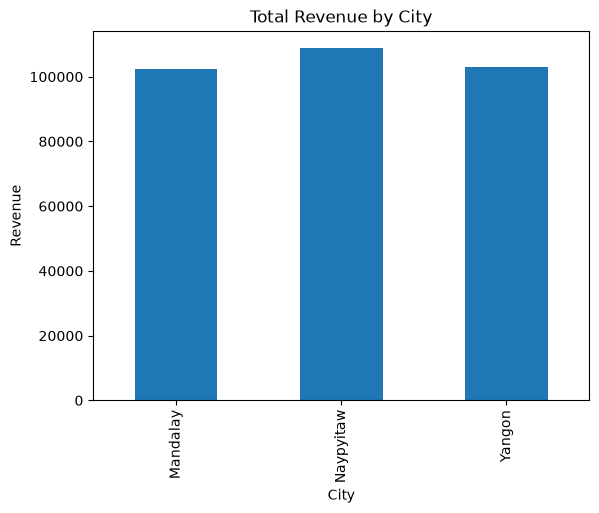

In [22]:
df.groupby("City")["total_revenue"].sum()
df.groupby("City")["total_revenue"].sum().idxmax()

df.groupby("City")["total_revenue"].sum().plot(kind="bar")
plt.title("Total Revenue by City")
plt.ylabel("Revenue")
plt.show()

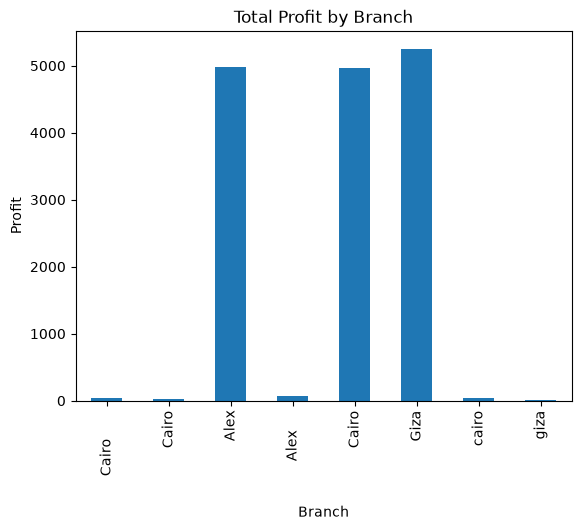

In [23]:
df.groupby("Branch")["gross_income"].sum()
df.groupby("Branch")["gross_income"].sum().idxmax()

df.groupby("Branch")["gross_income"].sum().plot(kind="bar")
plt.title("Total Profit by Branch")
plt.ylabel("Profit")
plt.show()

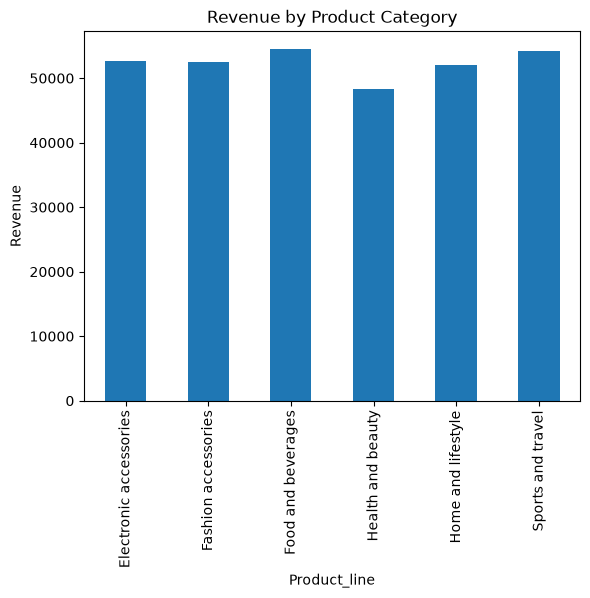

In [24]:
df.groupby("Product_line")["total_revenue"].sum()
df.groupby("Product_line")["total_revenue"].sum().idxmax()

df.groupby("Product_line")["total_revenue"].sum().plot(kind="bar")
plt.title("Revenue by Product Category")
plt.ylabel("Revenue")
plt.show()

In [25]:
df.groupby("Product_line")["gross_income"].sum()
df.groupby("Product_line")["gross_income"].sum().idxmax()

'Food and beverages'

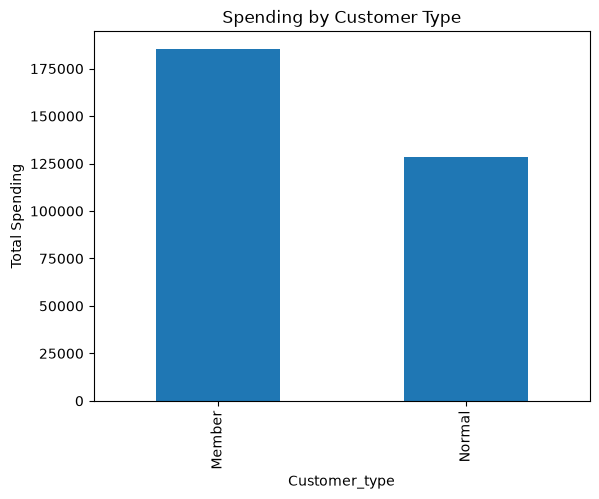

In [26]:
df.groupby("Customer_type")["total_revenue"].sum()
df.groupby("Customer_type")["total_revenue"].sum().idxmax()

df.groupby("Customer_type")["total_revenue"].sum().plot(kind="bar")
plt.title("Spending by Customer Type")
plt.ylabel("Total Spending")
plt.show()

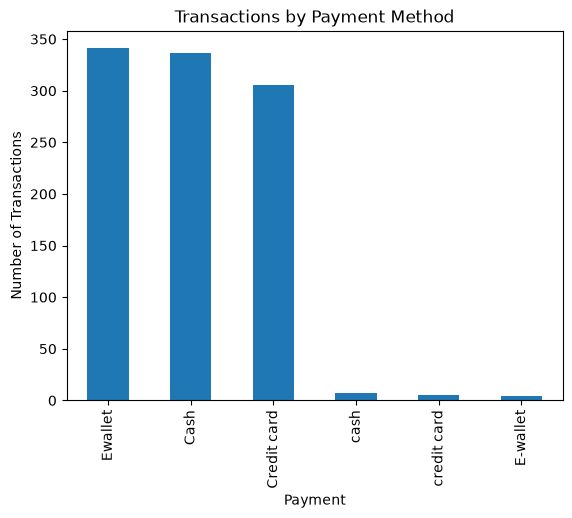

In [27]:
df["Payment"].value_counts()
df["Payment"].value_counts().idxmax()

df["Payment"].value_counts().plot(kind="bar")
plt.title("Transactions by Payment Method")
plt.ylabel("Number of Transactions")
plt.show()

In [28]:
df["total_revenue"].mean()

np.float64(321.83631762295084)

In [30]:
df[df["Satisfied"] == "Satisfied"].groupby("Branch").size() / df.groupby("Branch").size() * 100

Branch
      Cairo                  NaN
     Cairo             25.000000
Alex                   53.115727
Alex                         NaN
Cairo                  45.705521
Giza                   52.293578
cairo                 100.000000
giza                         NaN
dtype: float64

In [31]:
df.groupby("Day")["total_revenue"].sum()
df.groupby("Day")["total_revenue"].sum().idxmax()

np.float64(15.0)

In [32]:
df.groupby("Month")["total_revenue"].sum()
df.groupby("Month")["total_revenue"].sum().idxmax()

np.float64(1.0)

In [34]:
(df["Satisfied"] == "Satisfied").mean() * 100

np.float64(50.1)